# Four Finnish C-band radars: who is right, and one map from all of them

**Why.** In radarwow-verify notebook 06, Anjalankoski (fianj) saw only about a third of the gauge rain at every
distance: either its reflectivity calibration is 5-8 dB low, or water on its radome attenuated the signal while it
rained at the site. Neighbouring radars look at the same rain and settle it: a calibration error is a steady
difference against every neighbour; a wet radome only appears while it rains over the radar.

**Then the mosaic** (`radarwow.mosaic`): each radar's hourly totals from the single-radar chain, combined by a
quality index (beam height, blockage) on a common grid, checked against the FMI gauges.

Radars: Anjalankoski (fianj), Vihti (fivih, 147 km west), Kesalahti (fikes, 181 km north-east), Petajavesi
(fipet, 179 km north-north-west). 30 Aug 2023, 12-16 UTC. All data open (FMI on AWS; FMI open data).

In [1]:
# Colab: uncomment to install
!pip install -q pysteps opencv-python-headless rasterio "git+https://github.com/manmeet3591/radarwow-pipeline" "git+https://github.com/manmeet3591/radarwow-merging" "git+https://github.com/manmeet3591/radarwow-mosaic"

zsh:1: command not found: pip


In [2]:
import os
import warnings

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import Markdown, display

from radarwow.attenuation import Testud2000ZPHI
from radarwow.classification import melting_layer_from_volume
from radarwow.core import fmi_aws_files, open_volume
from radarwow.core.noise import signal_mask
from radarwow.estimation import below_melting_layer, polar_to_cartesian, to_fixed_azimuths, unique_tilts
from radarwow.estimation.vpr import beam_height_km
from radarwow.kdp import Vulpiani2012KDP
from radarwow.merging import leave_one_out, radar_at
from radarwow.mosaic import composite, mosaic_grid, overlap_difference, quality_index, to_grid
from radarwow.pipeline import hourly_totals
from radarwow.verify import basic_qc, fetch_fmi, gross_error_qc, t2m_freezing_level

FIG = "../docs/figures"
CACHE = os.path.expanduser("~/.cache/radarwow")
SITES = ["fianj", "fivih", "fikes", "fipet"]
START, END = "2023-08-30 12:00", "2023-08-30 16:00"
rad = {s: hourly_totals(s, START, END, n_tilts=3, blockage=True, source="fmi") for s in SITES}
grid = mosaic_grid(list(rad.values()), res_km=2.0)

## 1. Radar against radar
Every 15 minutes, the lowest tilt of each radar (attenuation-corrected reflectivity) on a common 2 km grid. Cells
are compared where both radars see rain (>= 15 dBZ) below the melting layer, with beam heights within 0.5 km of
each other (so they sample the same part of the rain) and less than 1 dB of attenuation along either path.

In [3]:
def lowest_tilt_on_grid(site, t):
    f = fmi_aws_files(site, t, t + pd.Timedelta(minutes=1), cache_dir=f"{CACHE}/fmi")[0][1]
    dt = open_volume(f, band="C")
    r = rad[site]
    fz = (t2m_freezing_level(t.floor("h"), r.attrs["radar_lat"], r.attrs["radar_lon"], f"{CACHE}/openmeteo") - r.attrs["radar_alt_m"]) / 1e3
    ml, _ = melting_layer_from_volume(dt)
    mlb = ml.bottom_km if ml.detected and abs(ml.top_km - fz) < 1.0 else fz - 0.5
    el, name = unique_tilts(dt)[0]
    ds = dt[name].to_dataset()
    ds = ds.isel(range=ds["range"].values <= 152e3)
    att = Testud2000ZPHI()(Vulpiani2012KDP()(ds, band="C"), band="C")
    ok = signal_mask(ds) & below_melting_layer(ds, ml_bottom_km=mlb) & (att["PIA"].values < 1.0)
    z = att["DBZH"].copy(data=np.where(ok, att["DBZH"].values, np.nan))
    h = z.copy(data=np.broadcast_to(beam_height_km(ds["range"].values, el) + r.attrs["radar_alt_m"] / 1e3, z.shape))
    cart = lambda da: polar_to_cartesian(to_fixed_azimuths(da), el, max_km=150, res_km=1.0).values  # noqa: E731
    return to_grid(cart(z), r, grid), to_grid(cart(h), r, grid)


PAIRS = [("fianj", "fivih"), ("fianj", "fikes"), ("fianj", "fipet"), ("fivih", "fipet")]
rows = []
for t in pd.date_range(START, pd.Timestamp(END) - pd.Timedelta(minutes=15), freq="15min"):
    zz = {s: lowest_tilt_on_grid(s, t) for s in SITES}
    for a, b in PAIRS:
        d, iqr, n = overlap_difference(zz[a][0], zz[b][0], zz[a][1], zz[b][1], np.ones(zz[a][0].shape, bool))
        rows.append(dict(time=t, pair=f"{a} - {b}", dZ=d, iqr=iqr, n=n))
cmp_ = pd.DataFrame(rows)
summ = cmp_.groupby("pair").agg(median_dZ_dB=("dZ", "median"), min_dZ=("dZ", "min"), max_dZ=("dZ", "max"), cells=("n", "sum")).round(1)
display(Markdown("**Reflectivity difference in overlap areas** (dB; median over 15-min times, and its range)\n\n" + summ.to_markdown()))

**Reflectivity difference in overlap areas** (dB; median over 15-min times, and its range)

| pair          |   median_dZ_dB |   min_dZ |   max_dZ |   cells |
|:--------------|---------------:|---------:|---------:|--------:|
| fianj - fikes |           -2.4 |     -5   |     -1.4 |    9820 |
| fianj - fipet |           -1.3 |     -2.7 |      0.3 |    8417 |
| fianj - fivih |           -1   |     -2.4 |      1.2 |    3895 |
| fivih - fipet |            1.3 |     -1.7 |      2.6 |    4421 |

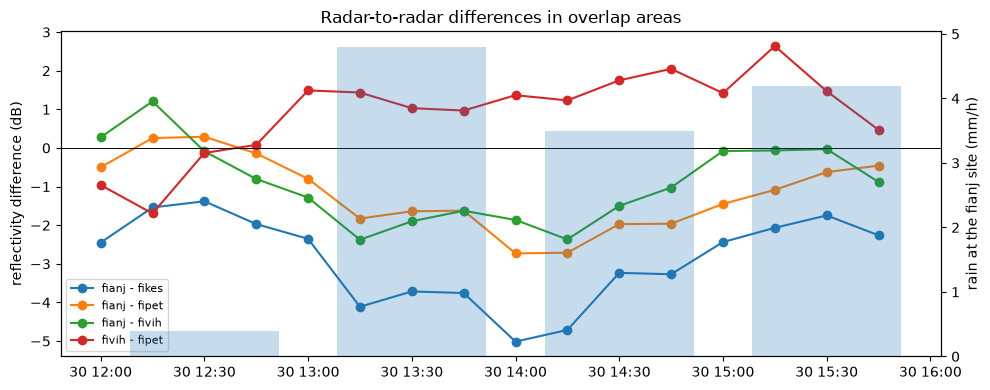

In [4]:
g_all = fetch_fmi(rad["fianj"].attrs["radar_lat"], rad["fianj"].attrs["radar_lon"], 145, START, END, f"{CACHE}/gauges")
site_g = g_all.assign(d=np.hypot((g_all.lat - rad["fianj"].attrs["radar_lat"]) * 111.2,
                                 (g_all.lon - rad["fianj"].attrs["radar_lon"]) * 111.2 * np.cos(np.deg2rad(60.9))))
site_g = site_g[site_g.d == site_g.d.min()]
fig, ax = plt.subplots(figsize=(10, 4))
for p, d in cmp_.groupby("pair"):
    ax.plot(d.time, d.dZ, "o-", label=p)
ax.axhline(0, color="k", lw=0.7)
ax2 = ax.twinx()
ax2.bar(site_g.time + pd.Timedelta(minutes=30), site_g.gauge_mm, width=0.03, alpha=0.25, color="C0", label="gauge 9 km from fianj")
ax2.set_ylabel("rain at the fianj site (mm/h)")
ax.set(ylabel="reflectivity difference (dB)", title="Radar-to-radar differences in overlap areas")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig(f"{FIG}/01_fmi_intercomparison.png", dpi=110)
plt.show()

## 2. Each radar, and the mosaic, against the gauges

In [5]:
lat_c, lon_c = float(grid.lat.mean()), float(grid.lon.mean())
g = pd.concat([fetch_fmi(r.attrs["radar_lat"], r.attrs["radar_lon"], 145, START, END, f"{CACHE}/gauges") for r in rad.values()])
g = g.drop_duplicates(["station", "time"]).reset_index(drop=True)
lon2, lat2 = np.meshgrid(grid.lon.values, grid.lat.values)
q = {s: np.nan_to_num(to_grid(quality_index(r["HEIGHT"].values, r["BLOCKAGE"].values), r, grid)) for s, r in rad.items()}
fields = {}
for t in rad["fianj"]["time"].values:
    per = {s: to_grid(r["RAIN"].sel(time=t).values, r, grid) for s, r in rad.items()}
    for s in SITES:
        fields[(s, t)] = per[s]
    fields[("mosaic (max quality)", t)], best, _ = composite([per[s] for s in SITES], [q[s] for s in SITES], "max")
    fields[("mosaic (weighted)", t)], _, _ = composite([per[s] for s in SITES], [q[s] for s in SITES], "weighted")
# grid coordinates in km for radar_at / merging
gx_axis = (grid.lon.values - lon_c) * 111.2 * np.cos(np.deg2rad(lat_c))
gy_axis = (grid.lat.values - lat_c) * 111.2
g["gx"] = (g.lon - lon_c) * 111.2 * np.cos(np.deg2rad(lat_c))
g["gy"] = (g.lat - lat_c) * 111.2
NAMES = SITES + ["mosaic (max quality)", "mosaic (weighted)"]
for k in NAMES:
    g[k] = np.nan
    for t, idx in g.groupby("time").groups.items():
        g.loc[idx, k] = radar_at(fields[(k, np.datetime64(t))], gx_axis, gy_axis, g.loc[idx, "gx"].values, g.loc[idx, "gy"].values)
g = gross_error_qc(basic_qc(g, radar_col="mosaic (max quality)"), radar_col="mosaic (max quality)")
ok = g[g.qc == "ok"]


def stats(e, r):
    m = np.isfinite(e) & np.isfinite(r)
    return dict(n=int(m.sum()), bias=e[m].sum() / r[m].sum(), MAE=np.mean(np.abs(e[m] - r[m])), corr=np.corrcoef(e[m], r[m])[0, 1])


tab = pd.DataFrame([dict(estimate=k, **stats(ok[k].values, ok.gauge_mm.values)) for k in NAMES])
display(Markdown(f"{g.station.nunique()} gauges, QC: " + ", ".join(f"{a}: {b}" for a, b in g.qc.value_counts().items())
                 + "\n\n**At the gauges each radar covers** (bias = radar / gauge)\n\n" + tab.round(2).to_markdown(index=False)))

52 gauges, QC: ok: 207, no radar value: 1

**At the gauges each radar covers** (bias = radar / gauge)

| estimate             |   n |   bias |   MAE |   corr |
|:---------------------|----:|-------:|------:|-------:|
| fianj                |  92 |   0.35 |  1.01 |   0.88 |
| fivih                | 125 |   0.43 |  0.61 |   0.93 |
| fikes                |  36 |   1.37 |  0.28 |   0.91 |
| fipet                |  65 |   0.65 |  0.34 |   0.74 |
| mosaic (max quality) | 207 |   0.52 |  0.54 |   0.83 |
| mosaic (weighted)    | 207 |   0.53 |  0.52 |   0.86 |

## 3. Mosaic plus gauges (leave-one-out)

In [6]:
loo = []
for t, gt in ok.groupby("time"):
    f = fields[("mosaic (max quality)", np.datetime64(t))]
    for m in ["radar only", "MFB", "conditional merging", "KED"]:
        loo.append(pd.DataFrame(dict(method=m, gauge=gt.gauge_mm.values,
                                     est=leave_one_out(m, f, gx_axis, gy_axis, gt.gx.values, gt.gy.values, gt.gauge_mm.values))))
loo = pd.concat(loo)
display(Markdown("**Mosaic (max quality) merged with gauges, leave-one-out**\n\n"
                 + pd.DataFrame([dict(method=m, **stats(d.est.values, d.gauge.values)) for m, d in loo.groupby("method", sort=False)]).round(2).to_markdown(index=False)))

**Mosaic (max quality) merged with gauges, leave-one-out**

| method              |   n |   bias |   MAE |   corr |
|:--------------------|----:|-------:|------:|-------:|
| radar only          | 207 |   0.52 |  0.54 |   0.83 |
| MFB                 | 207 |   1.01 |  0.5  |   0.82 |
| conditional merging | 207 |   1.03 |  0.34 |   0.91 |
| KED                 | 207 |   1.06 |  0.37 |   0.9  |

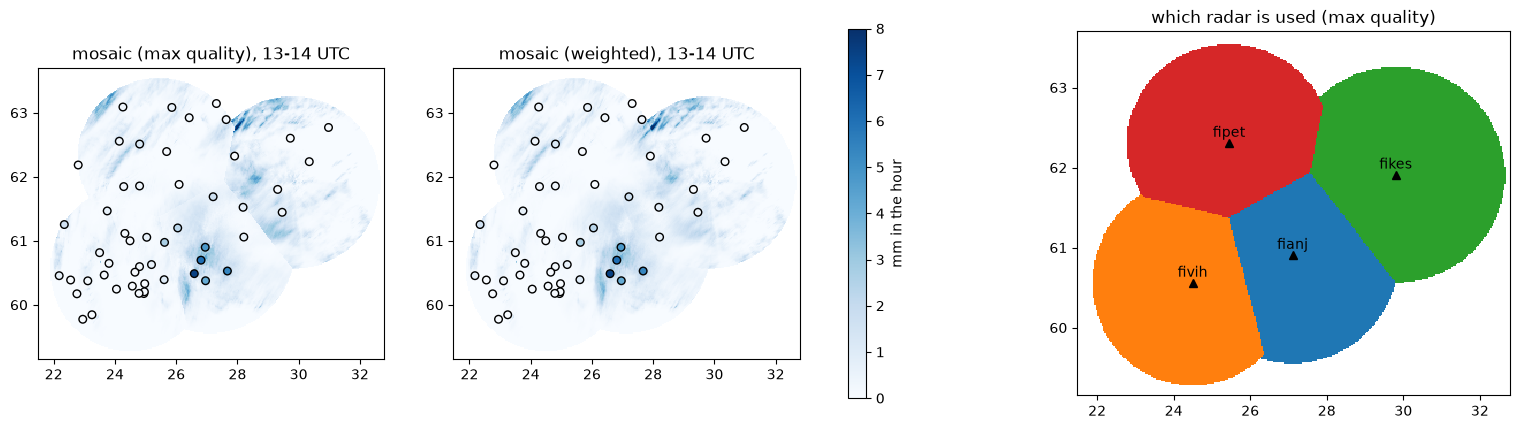

In [7]:
t = np.datetime64("2023-08-30T13:00")
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
for ax, k in zip(axes[:2], ["mosaic (max quality)", "mosaic (weighted)"]):
    p = ax.pcolormesh(grid.lon, grid.lat, np.ma.masked_invalid(fields[(k, t)]), cmap="Blues", vmin=0, vmax=8, shading="auto")
    gt = ok[ok.time == pd.Timestamp(t)]
    ax.scatter(gt.lon, gt.lat, c=gt.gauge_mm, cmap="Blues", vmin=0, vmax=8, s=30, edgecolors="k")
    ax.set(title=f"{k}, 13-14 UTC", aspect=1 / np.cos(np.deg2rad(lat_c)))
_, best, _ = composite([fields[(s, t)] for s in SITES], [q[s] for s in SITES], "max")
axes[2].pcolormesh(grid.lon, grid.lat, np.ma.masked_less(best, 0), cmap="tab10", vmin=0, vmax=9, shading="auto")
for i, s in enumerate(SITES):
    axes[2].plot(rad[s].attrs["radar_lon"], rad[s].attrs["radar_lat"], "k^")
    axes[2].text(rad[s].attrs["radar_lon"], rad[s].attrs["radar_lat"] + 0.08, s, ha="center")
axes[2].set(title="which radar is used (max quality)", aspect=1 / np.cos(np.deg2rad(lat_c)))
fig.colorbar(p, ax=axes[:2], label="mm in the hour", shrink=0.8)
fig.savefig(f"{FIG}/02_finland_mosaic.png", dpi=90, bbox_inches="tight")
plt.show()

## Takeaways
- **Anjalankoski's calibration is not the problem.** In the overlap areas it reads 1-2.4 dB below its three
  neighbours (median over the afternoon); the control pair Vihti-Petajavesi differs by 1.3 dB. A 5-8 dB error is
  ruled out.
- **A wet radome probably adds about 2 dB while it rains at the site.** fianj's difference to all three neighbours
  deepens by ~1.5-2.5 dB from 13:00 to 14:45, the heaviest rain at its site (4.8 mm/h in the gauge 9 km away), and
  the control pair does not move. The signal is weaker during the 15-16 UTC rain, so this is suggestive, not proven.
- **The shortfall against the gauges is shared and varies by area, not by radar:** 0.35 (fianj), 0.43 (fivih),
  0.65 (fipet), 1.37 (fikes, light rain, 36 gauge-hours), while the radars agree with each other within 1-2.4 dB.
  So most of it comes from how reflectivity is turned into rain for this rain (the kind of problem the adaptive
  alpha solved at S band) or from rain forming below the beam, not from any one radar. Not resolved here.
- **A bug found by the mosaic.** Petajavesi stores PHIDP with a system offset of ~356 deg, so its phase folds at
  0/360 on every ray; our unfolding left 356 deg jumps, which ZPHI and R(A) turned into heavy rain (5.8x the gauges).
  radarwow-kdp now rotates each sweep to its circular-mean phase first; Petajavesi's ray phase span (99th
  percentile) fell from 345 to 18 deg, and the other seven radars changed by 0.3 % or less.
- **The mosaic** (max-quality and quality-weighted give nearly the same result) correlates with the gauges at
  0.83-0.86 with the shortfall above (bias 0.52). **With gauges** (conditional merging, leave-one-out) the error
  falls 37 % and the bias goes to 1.03, correlation 0.91.